# EHF Backtest Playground

Pull real data through `FMPProvider`, run a cost-aware backtest, plot it, log it to the registry, sweep params. **Tweak anything and re-run.**

Kernel: select the **`.venv311`** interpreter (`.venv311/bin/python`). Data is cached to `data/cache/`, runs to `results/` (both git-ignored).

In [1]:
%matplotlib inline
import os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Anchor CWD at the repo root so data/cache and results/ land in the right place.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ehf.research.data.fmp_provider import FMPProvider
from ehf.research.data.schema import Timeframe
from ehf.research.data.quality import DataQualityWarning
from ehf.research.backtest.panel import Panel
from ehf.research.backtest.engine import run_backtest
from ehf.research.config.spec import RunSpec, UniverseSpec, CostConfig, FillModel
from ehf.research.results.registry import ExperimentRegistry
import ehf.research.signals as sig

# Never hide data-quality warnings (e.g. "FMP only returned 3 months of intraday").
warnings.filterwarnings("always", category=DataQualityWarning)

print("repo root:", ROOT)

repo root: /Users/andrewantczak/Work/Eagle_Hill_Fund/eagle_hill_fund


## 1 - Pull data (live FMP, cached after first call)
Change `SYMBOLS` / dates and re-run. First pull hits the API; repeats read the parquet cache.

In [2]:
prov = FMPProvider()
SYMBOLS = prov.random_symbols(10)
print(SYMBOLS)
START, END = "2006-01-01", "2024-12-31"

# Any timeframe works over any range — intraday (HOUR/MINUTE) is auto-chunked under
# FMP's per-request cap and stitched, so you get the full span. Long intraday pulls
# are slower the first time, then cached. If FMP genuinely lacks data that far back,
# you'll get a DataQualityWarning showing the real span recovered.
bars = prov.get_bars(SYMBOLS, START, END, Timeframe.HOUR)
print(f"{len(bars)} rows | {bars['symbol'].nunique()} symbols | "
      f"{bars['timestamp'].min().date()} -> {bars['timestamp'].max().date()}")
bars.head()

🔥 M3 Ultra Mac Studio detected! (28 cores, 96.0GB RAM)
📊 Optimal settings: 168 workers


['ALNY', 'BANC', 'BN', 'CHRW', 'EPR', 'ETSY', 'RBLX', 'ROST', 'SNPS', 'TECH']


250431 rows | 10 symbols | 2006-01-03 -> 2024-12-31


,symbol,timestamp,open,high,low,close,volume
0,ALNY,2006-01-03 14:30:00+00:00,13.39,13.480,13.26,13.33,12424.0
1,ALNY,2006-01-03 15:30:00+00:00,13.33,13.330,13.15,13.19,14563.0
2,ALNY,2006-01-03 16:30:00+00:00,13.18,13.260,13.10,13.15,7775.0
3,ALNY,2006-01-03 17:30:00+00:00,13.12,13.152,13.08,13.13,4045.0
4,ALNY,2006-01-03 18:30:00+00:00,13.08,13.090,12.89,12.94,21170.0


## 2 - Run a backtest  (tweak `strategy` / `params` here)
Strategies: `"tsmom"` (momentum, vol-scaled) or `"rise_fall"` (mean reversion). Costs and t+1-open fills are on by default.

In [3]:
spec = RunSpec(
    strategy="tsmom",
    params={"lookback": 126, "vol_window": 40, "target_vol": 0.12},
    universe=UniverseSpec(symbols=tuple(SYMBOLS)),
    start=START, end=END,
    costs=CostConfig(slippage_bps=1.0),   # set frictionless=True to debug (labeled, no costs)
    fill_model=FillModel.NEXT_OPEN,
)
res = run_backtest(spec, bars)
pd.Series(res.metrics).round(4)

n_bars           33337.0000
total_return        -0.7311
cagr                -0.0625
ann_vol              0.1471
sharpe              -0.3652
sortino             -0.4504
max_drawdown        -0.7602
calmar              -0.0822
hit_rate             0.4967
n_trades        246963.0000
avg_turnover         0.0963
dtype: float64

## 3 - Plot equity + drawdown

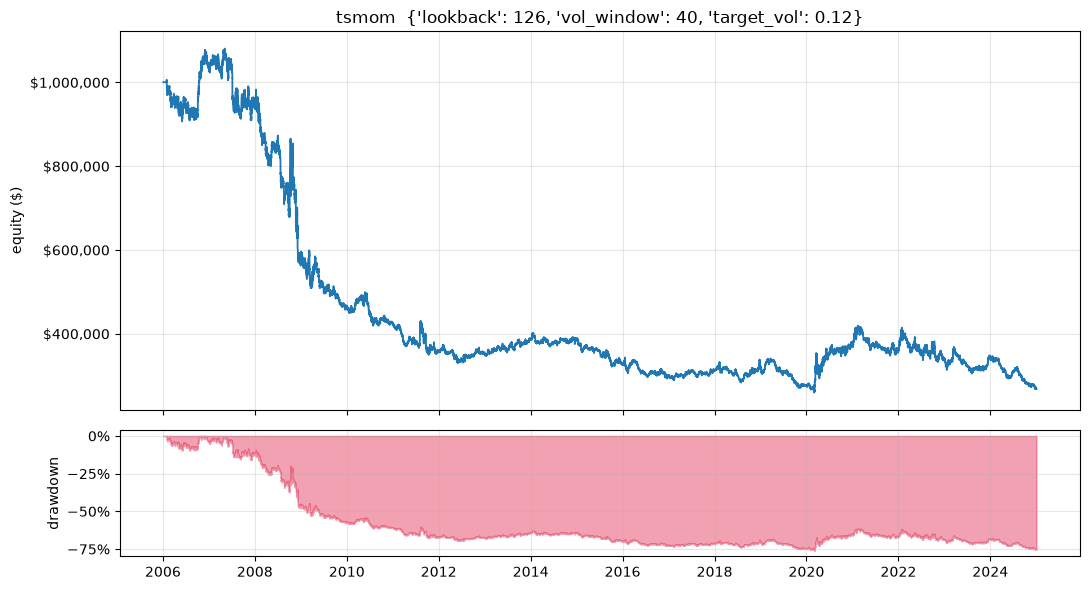

In [4]:
import matplotlib.ticker as mtick

eq = res.equity.set_index("timestamp")
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, height_ratios=[3, 1])
ax[0].plot(eq.index, eq["equity"], lw=1.3)
ax[0].set_title(f"{spec.strategy}  {spec.params}")
ax[0].set_ylabel("equity ($)"); ax[0].grid(alpha=.3)
ax[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}"))  # $1,234,567
dd = eq["equity"] / eq["equity"].cummax() - 1.0
ax[1].fill_between(eq.index, dd, 0, color="crimson", alpha=.4)
ax[1].set_ylabel("drawdown"); ax[1].grid(alpha=.3)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1.0))  # -12% not -0.12
plt.tight_layout(); plt.show()

## 4 - Log to the registry, then query across runs
Every run is reproducible by its `config_hash`. Re-running an identical spec is idempotent (skipped).

In [5]:
reg = ExperimentRegistry()
h = reg.log_run(spec, res)
print("logged:", h)
reg.query("ORDER BY m_sharpe DESC")[
    ["strategy", "config_hash", "m_sharpe", "m_cagr", "m_max_drawdown", "m_n_trades"]
]

logged: e3184cd255ac79fa


,strategy,config_hash,m_sharpe,m_cagr,m_max_drawdown,m_n_trades
0,rise_fall,d9d82d47bfb8b0d0,3.497102,0.360883,-0.021380,42.0
1,rise_fall,0b3f246533bba789,3.216390,0.332122,-0.021380,40.0
2,tsmom,239745b3aa081ffe,3.200551,0.186874,-0.019213,3010.0
3,rise_fall,2d787f48d5c6c54e,3.125003,0.955788,-0.063436,102.0
4,rise_fall,14fb0b1fcbfb89b3,2.664080,0.705687,-0.094719,84.0
...,...,...,...,...,...,...
151,rise_fall,01ddc2e32a9331ac,-2.228608,-0.548202,-0.240196,385.0
152,rise_fall,67211adc1b534d8d,-2.310901,-0.561868,-0.261906,338.0
153,rise_fall,4f8c7f8010400f24,-2.318807,-0.566115,-0.215113,160.0
154,rise_fall,2bf97de6f166dfe8,-2.363168,-0.554159,-0.254919,388.0


## 5 - A parameter sweep — parallel across ALL your cores
`run_sweep` fans every cell across a process pool (workers compute **and** write their own parquet; the parent bulk-logs in one transaction with a single git call). On the M3 Ultra this runs ~12-17x faster than a serial loop — fully compute-bound. Every cell is logged and tagged with one `sweep_id`.

In [6]:
from ehf.research.backtest.sweep import run_sweep

# Parallel sweep across all cores: workers compute + write parquet; parent bulk-logs.
sweep_grid = {
    "drop_pct": [0.005, 0.01],
    "rise_pct": [0.02, 0.04],
    "trend_window": [50, 100, 200],
    "max_hold": [10, 20],
}  # 2*2*3*2 = 24 cells
base = RunSpec(
    strategy="rise_fall",
    params={"atr_window": 14},
    universe=UniverseSpec(symbols=tuple(SYMBOLS)),
    start=START, end=END,
    costs=CostConfig(slippage_bps=1.0),
)
sweep = run_sweep(base, sweep_grid, bars, registry=reg)   # n_workers defaults to ALL cores
print(f"{len(sweep)} cells swept in parallel")
sweep.sort_values("m_sharpe", ascending=False)[
    ["config_hash", "m_sharpe", "m_cagr", "m_max_drawdown", "m_n_trades"]
].head(10)

168 cells swept in parallel


,config_hash,m_sharpe,m_cagr,m_max_drawdown,m_n_trades
149,d9d82d47bfb8b0d0,3.497102,0.360883,-0.021380,42.0
7,0b3f246533bba789,3.216390,0.332122,-0.021380,40.0
29,2d787f48d5c6c54e,3.125003,0.955788,-0.063436,102.0
15,14fb0b1fcbfb89b3,2.664080,0.705687,-0.094719,84.0
102,9b88ca907acb00ff,2.473169,2.529860,-0.136831,205.0
73,70801a045a54780f,2.360827,2.927536,-0.122440,190.0
22,23190c9ca2114cab,2.356246,2.470092,-0.116769,235.0
8,0c98816b7a0c2e04,2.317972,2.413061,-0.122440,164.0
30,2ec8760f2930b9b4,2.307902,2.179753,-0.122227,442.0
64,65ba9350aade80c5,2.202428,0.587920,-0.105049,340.0


## 6 - Complexity bonus: a regime signal
Rolling permutation entropy on SPY (low = orderly/trending, high = noisy). The raw material for the regime-gate application.

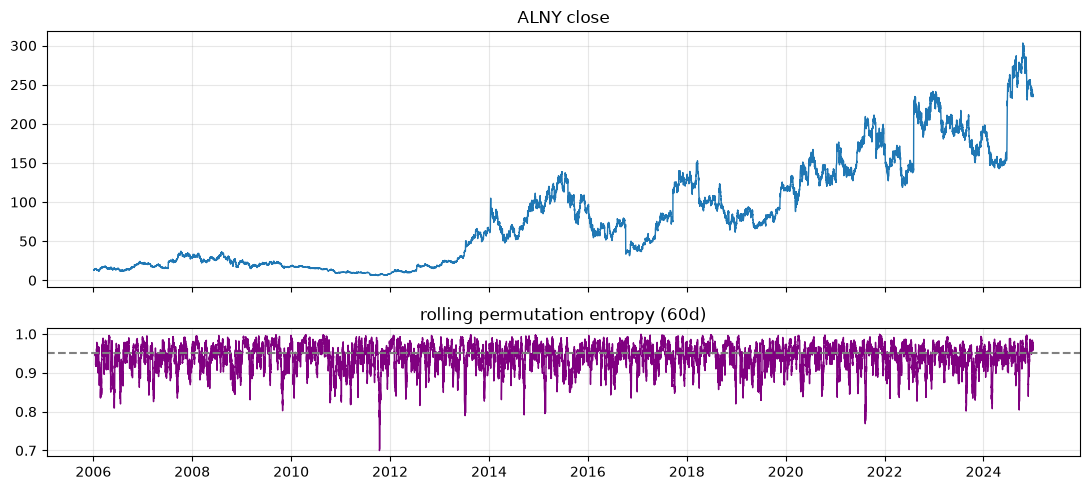

In [7]:
sym0 = SYMBOLS[0]   # works for whatever universe you picked
close = Panel.from_bars(bars).close[sym0].dropna()
pe = sig.rolling_permutation_entropy(close, 60)
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True, height_ratios=[2, 1])
ax[0].plot(close.index, close, lw=1); ax[0].set_title(f"{sym0} close"); ax[0].grid(alpha=.3)
ax[1].plot(pe.index, pe, color="purple", lw=1)
ax[1].axhline(0.95, ls="--", color="gray"); ax[1].set_title("rolling permutation entropy (60d)")
ax[1].grid(alpha=.3); plt.tight_layout(); plt.show()